
# Emotion Classification — Classroom Demo (Hugging Face Transformers)

In this notebook, you will train a **text classifier** that predicts emotions in short texts.
We will use:
- The **dair-ai/emotion** dataset (6 classes: anger, fear, joy, love, sadness, surprise).
- A compact Transformer model: **DistilBERT**.
- A clear comparison: predictions **before training** vs **after training** on the same samples.

> **Learning goals**
> - Load a dataset from the internet using `datasets`.
> - Tokenize text for Transformer models.
> - Fine-tune a classifier with the `Trainer` API.
> - Evaluate with accuracy/F1 and inspect predictions qualitatively.


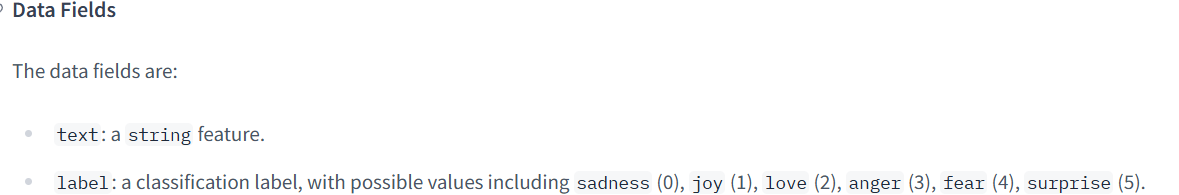

In [ ]:
"""
Setup cell: Install required libraries for emotion classification.
- `datasets` to load the dair-ai/emotion dataset.
- `transformers` for modeling and training.
- `evaluate` and `scikit-learn` for metrics.
"""
!pip -q install datasets==2.21.0 transformers==4.44.2 accelerate==0.34.2 evaluate==0.4.2 scikit-learn==1.6


In [ ]:
!pip install evaluate

In [ ]:
"""
Imports and basic configuration.

What this does:
- Imports core libraries: datasets, transformers, torch, numpy, sklearn, evaluate.
- Sets a fixed random seed for reproducibility.
- Chooses device (GPU if available, else CPU).
"""
import random
import numpy as np
import torch

from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)
import evaluate
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


In [ ]:
"""
Load the **dair-ai/emotion** dataset.

- Small (train ~16k, val ~2k, test ~2k).
- 6 balanced emotions: anger, fear, joy, love, sadness, surprise.

Splits:
- train / validation / test

Fields:
- `text`: the input sentence
- `label`: integer class id (0..5), with `dataset['train'].features['label'].names` holding the names.
"""
dataset = load_dataset("dair-ai/emotion")

In [ ]:
"""
Inspect label names and a few samples.
"""
label_names = dataset["train"].features["label"].names ### label names present in training data
id2label = {i: l for i, l in enumerate(label_names)} ### {0 : "sadness", 1 : "joy", ...}
label2id = {l: i for i, l in enumerate(label_names)} ### {"sadness" : 0, "joy" : 1, ...}
print("Labels:", label_names)

for i in range(3):
    row = dataset["train"][i]
    print(f"[Train {i}] text={row['text']!r} | label={row['label']} ({label_names[row['label']]})")


## WORD CLOUD FOR EVERY EMOTION

In [ ]:

# CLASS-SPECIFIC WORD CLOUDS
# Class-vs-Rest Log-Odds Association

import re
import math
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from wordcloud import WordCloud, STOPWORDS



# 1. SETTINGS




print("Labels:", label_names)



# 2. STOPWORDS


stopwords = set(STOPWORDS).union({
    # conversational / dataset-specific words
    "im", "ive", "id", "ill", "dont", "didnt",
    "doesnt", "isnt", "wasnt", "werent",
    "cant", "couldnt", "wouldnt", "shouldnt",
    "wont", "havent", "hasnt", "hadnt",

    # generic words
    "feel", "feeling",
    "really",
    "get", "got", "getting",
    "like",
    "one",
    "would",
    "could",
    "should",
    "know",
    "think",
    "make",
    "made",
    "people",
    "time",
    "way",
    "thing",
    "horny",
    "things",
    "little",
    "much",
    "still",
    "even",
    "back",
    "want",
    "going",
    "go",
    "day",
    "life",
    "see",
    "say",
    "said",
    "felt",
    "feelings"
})



# 3. TOKENIZER


def tokenize(text):
    """
    Simple tokenizer:
    - lowercase
    - keeps alphabetic words
    - removes stopwords
    - removes very short words
    """

    text = text.lower()

    words = re.findall(r"[a-z]+", text)

    words = [
        word
        for word in words
        if word not in stopwords
        and len(word) >= 3
    ]

    return words



# 4. COLLECT TEXT FOR EACH EMOTION

emotion_tokens = {} ### initialized empty

for label_id, label_name in enumerate(label_names):

    texts = [ ### collection of samples where for each label
        row["text"] ### Every row has text and label in the dataset
        for row in dataset["train"] ### for every row in the train set provided by huggingface
        if row["label"] == label_id 
    ]

    # Tokenize every text
    tokens = [] ### initialize empty

    for text in texts:
        tokens.extend(tokenize(text))

    emotion_tokens[label_id] = tokens

    print(
        f"{label_name.upper():10s} -> "
        f"{len(texts):5d} texts, "
        f"{len(tokens):7d} tokens"
    )



# 5. CREATE WORD COUNTS


emotion_counts = {}

for label_id in emotion_tokens:
    emotion_counts[label_id] = Counter(emotion_tokens[label_id])


# Total counts across the complete dataset

total_counts = Counter()

for counts in emotion_counts.values():
    total_counts.update(counts)



# 6. CLASS-vs-REST LOG-ODDS

def calculate_log_odds(class_counts, rest_counts, alpha=0.01):
    """
    Calculate smoothed log-odds ratio.

    Positive score:
        word is more associated with this emotion

    Negative score:
        word is more associated with the other emotions
    """

    # Total number of tokens
    class_total = sum(class_counts.values())
    rest_total = sum(rest_counts.values())

    # Vocabulary
    vocabulary = set(class_counts.keys()) | set(rest_counts.keys())

    scores = {}

    for word in vocabulary:

        # Word count in current emotion
        class_word_count = class_counts.get(word, 0)

        # Word count in all other emotions
        rest_word_count = rest_counts.get(word, 0)

        # Smoothed probabilities
        p_class = (
            class_word_count + alpha
        ) / (
            class_total + alpha * len(vocabulary)
        )

        p_rest = (
            rest_word_count + alpha
        ) / (
            rest_total + alpha * len(vocabulary)
        )

        # Log odds ratio
        score = math.log(p_class / p_rest)

        scores[word] = score

    return scores



# 7. CALCULATE CLASS-SPECIFIC SCORES


emotion_scores = {}

for label_id, label_name in enumerate(label_names):

    # Current emotion
    class_counts = emotion_counts[label_id]

    # All OTHER emotions
    rest_counts = Counter()

    for other_label_id in emotion_counts:

        if other_label_id != label_id:
            rest_counts.update(
                emotion_counts[other_label_id]
            )

    # Calculate association
    scores = calculate_log_odds(
        class_counts,
        rest_counts,
        alpha=0.01
    )

    emotion_scores[label_id] = scores


# 8. DISPLAY TOP DISTINCTIVE WORDS


print("\n" + "=" * 70)
print("TOP CLASS-SPECIFIC WORDS")
print("=" * 70)

for label_id, label_name in enumerate(label_names):

    scores = emotion_scores[label_id]

    # Sort by association with this class
    top_words = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:30]

    print(f"\n{label_name.upper()}")
    print("-" * 40)

    for word, score in top_words:
        print(f"{word:20s} {score:.3f}")



# 9. GENERATE CLASS-SPECIFIC WORD CLOUDS


fig, axes = plt.subplots(
    2,
    3,
    figsize=(20, 11)
)

for label_id, label_name in enumerate(label_names):

    scores = emotion_scores[label_id]

    
    # Only keep POSITIVE association scores


    positive_scores = {
        word: score
        for word, score in scores.items()
        if score > 0
    }

    # Keep only the strongest words

    positive_scores = dict(
        sorted(
            positive_scores.items(),
            key=lambda x: x[1],
            reverse=True
        )[:100]
    )


    # Generate word cloud


    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        max_words=100,
        collocations=False,
        relative_scaling=0.5,
        min_font_size=10
    ).generate_from_frequencies(
        positive_scores
    )

    
    # Plot

    ax = axes[label_id // 3, label_id % 3]

    ax.imshow(
        wordcloud,
        interpolation="bilinear"
    )

    ax.axis("off")

    ax.set_title(
        label_name.upper(),
        fontsize=18,
        fontweight="bold"
    )


plt.tight_layout()
plt.show()

## ILLUSTRATION OF THE SCORING MECHANISM

score = natural logarithm of odds ratio

$$
\boxed{
\text{Score}
=
\log
\left(
\frac{
P(\text{word}\mid\text{SADNESS})
}{
P(\text{word}\mid\text{OTHER})
}
\right)
}
$$

$$
=
\log
\left(
\frac{x/30,000}
{y/(\text{Total}-30,000)}
\right)
$$



## WORD CLOUD WITHOUT SCORING

In [ ]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Stopwords
# --------------------------------------------------

stopwords = STOPWORDS.union({
    "im", "ive", "id", "ill",
    "dont", "didnt", "doesnt",
    "isnt", "wasnt", "werent",
    "cant", "couldnt", "wouldnt",
    "shouldnt", "wont",

    "feel", "feeling",
    "really",
    "get", "got", "getting",
    "like", "one", "would",
    "could", "should",
})


# --------------------------------------------------
# 2. Create 2 × 3 grid
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 11)
)


# --------------------------------------------------
# 3. Generate one word cloud per emotion
# --------------------------------------------------

for label_id, label_name in enumerate(label_names):

    # Get texts belonging to this emotion
    texts = [
        row["text"]
        for row in dataset["train"]
        if row["label"] == label_id
    ]

    # Combine all texts
    combined_text = " ".join(texts)

    # Generate word cloud based ONLY on frequency
    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        stopwords=stopwords,
        max_words=100,
        collocations=False
    ).generate(combined_text)

    # Select subplot
    ax = axes[label_id // 3, label_id % 3]

    # Display
    ax.imshow(
        wordcloud,
        interpolation="bilinear"
    )

    ax.axis("off")

    ax.set_title(
        label_name.upper(),
        fontsize=18,
        fontweight="bold"
    )


# --------------------------------------------------
# 4. Final layout
# --------------------------------------------------

plt.tight_layout()
plt.show()

## MODEL SELECTION

In [ ]:
"""
Create the tokenizer and the classification model.

Model choice:
- We set `num_labels` to match the dataset (6 emotions).

We'll use this same model for **before** and **after** training checks.
"""
model_name = "distilbert-base-uncased" ### select the model
tokenizer = AutoTokenizer.from_pretrained(model_name) ### load tokenizer associated with the model
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=len(label_names), id2label=id2label, label2id=label2id
).to(device)  ### classification head added to pre-trained model

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
### pads shorter sequences for batching

In [ ]:
"""
Tokenize text examples.

Notes:
- `truncation=True` ensures sequences fit within the model's max length (512 tokens for DistilBERT).
- Padding will be handled dynamically by the `DataCollatorWithPadding` during batching.
"""
def preprocess_function(examples):
    return tokenizer(examples["text"], truncation=True)

tokenized_dataset = dataset.map(preprocess_function, batched=True)
tokenized_dataset


In [ ]:
"""
Define evaluation metrics.

We compute:
- Accuracy
- Macro F1 (averages F1 across classes equally)

The `Trainer` will call `compute_metrics` during evaluation.
"""
def compute_metrics(eval_pred):
    logits, labels = eval_pred ### logits : model prediction of every label; 
    #labels : correct label from the dataset
    preds = np.argmax(logits, axis=-1) ### prediction = highest logit
    acc = accuracy_score(labels, preds) ### accuracy of predictions
    f1 = f1_score(labels, preds, average="macro") ### macro-f1 of predictions
    return {"accuracy": acc, "f1_macro": f1}


In [ ]:
"""
Inspect predictions **before training**.

Goal:
- Show how the model behaves with a randomly initialized classification head (pretrained encoder).
- Provide a baseline to compare with **after** fine-tuning.

What we do:
- Select a few validation samples.
- Run the model to get logits → probabilities.
- Print predicted label with confidence along with the gold label.
"""
from torch.nn.functional import softmax

def predict_texts(text_list):
    enc = tokenizer(text_list, padding=True, truncation=True, return_tensors="pt")
    enc = {k: v.to(device) for k, v in enc.items()}
    with torch.no_grad(): ### freeze model for inference
        outputs = model(**enc)
        probs = softmax(outputs.logits, dim=-1).cpu().numpy() ### calculate probability for every logit
    preds = probs.argmax(axis=-1)
    return probs, preds

sample_indices = [0, 1, 7, 3, 4] #preview from validation set
val = dataset["validation"]
sample_texts = [val[i]["text"] for i in sample_indices]
sample_labels = [val[i]["label"] for i in sample_indices]

probs_before, preds_before = predict_texts(sample_texts)

for i, txt in enumerate(sample_texts):
    gold = sample_labels[i]
    pred = preds_before[i]
    print(f"Text: {txt!r}")
    print(f"  Gold: {gold} ({label_names[gold]})")
    print(f"  Pred (before): {pred} ({label_names[pred]})  probs={probs_before[i].round(3)}")
    print("-"*80)


In [ ]:
"""
Fine-tune the model.

Training settings (classroom-friendly):
- 1 epoch (increase to 2-3+ for better results).
- Moderate batch size suitable for typical GPU/CPU constraints.
- Evaluate each epoch and print metrics.

Tips:
- If using CPU only, keep epochs small for time constraints.
- Students can experiment with epochs and learning rate later.
"""
BATCH_SIZE = 16
EPOCHS = 1

training_args = TrainingArguments(
    output_dir="emotion-distilbert",
    num_train_epochs=EPOCHS, ###
    per_device_train_batch_size=BATCH_SIZE, ###
    per_device_eval_batch_size=BATCH_SIZE, ###
    eval_strategy="steps", ### validation step-wise
    logging_steps=50, ### log checkpoint after 50 steps per epoch
    learning_rate=2e-5, ###
    weight_decay=0.01, ###
    fp16=torch.cuda.is_available(), ###
    report_to="none", 
    save_strategy="no",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()
metrics = trainer.evaluate()
print("Validation metrics:", metrics)


In [ ]:
"""
Inspect predictions **after training** on the same validation samples.

What to expect:
- Higher confidence and more correct predictions vs before training.
"""
probs_after, preds_after = predict_texts(sample_texts)

for i, txt in enumerate(sample_texts):
    gold = sample_labels[i]
    pred = preds_after[i]
    print(f"Text: {txt!r}")
    print(f"  Gold: {gold} ({label_names[gold]})")
    print(f"  Pred (after):  {pred} ({label_names[pred]})  probs={probs_after[i].round(3)}")
    print("-"*80)
#Labels: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


## Exercises

- Increase `num_train_epochs` to **3** and compare validation accuracy/F1.
- Try different base models (e.g., `bert-base-uncased`, `roberta-base`).
```
model_name = "google-bert/bert-base-uncased"
```

```
model_name = "FacebookAI/roberta-base"
```
- Build a confusion matrix to see which emotions get confused.
- Test the trained model on some examples that do not use "emotion" words


# Exercise : Build a confusion matrix to see which emotions get confused.

In [ ]:

# Confusion Matrix on Validation Set


import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Run the fine-tuned model on the validation set
pred_output = ____________________( ### take the predictions from trainer
    tokenized_dataset[___________]  ### which split of dataset?
)

# 2. Gold labels
y_true = pred_output.label_ids

# 3. Predicted labels
y_pred = _____________(
    __________________,
    axis=-1
)

# 4. Emotion names in correct label order
emotion_names = [
    "sadness",
    "joy",
    "love",
    "anger",
    "fear",
    "surprise"
]

# 5. Create confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(6)
)

# 6. Display confusion matrix
fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=________________ #what labels should be displayed on each axis?
)

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues"
)

plt.title("Emotion Classification Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Solution : 

In [ ]:

# Confusion Matrix on Validation Set


import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Run the fine-tuned model on the validation set
pred_output = trainer.predict(
    tokenized_dataset["validation"]
)

# 2. Gold labels
y_true = pred_output.label_ids

# 3. Predicted labels
y_pred = np.argmax(
    pred_output.predictions,
    axis=-1
)

# 4. Emotion names in correct label order
emotion_names = [
    "sadness",
    "joy",
    "love",
    "anger",
    "fear",
    "surprise"
]

# 5. Create confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(6)
)

# 6. Display confusion matrix
fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=emotion_names
)

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues"
)

plt.title("Emotion Classification Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Exercise 2 : Interpret the confusing emotions from the above confusion matrix

- Write down the top 2 emotions the model is confusing.
- Write down the interpretation for each.

## ILLUSTRATION

Test on samples with no emotion words.

In [ ]:
import torch
import numpy as np

# ---------------------------------------------------------
# 1. Emotion labels
# ---------------------------------------------------------

emotion_names = [
    "sadness",
    "joy",
    "love",
    "anger",
    "fear",
    "surprise"
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)
model.eval()


# ---------------------------------------------------------
# 2. Prediction function
# ---------------------------------------------------------

def predict_emotion(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    probs = torch.softmax(
        outputs.logits,
        dim=-1
    )[0].cpu().numpy()

    pred_id = np.argmax(probs)

    return {
        "label": emotion_names[pred_id],
        "confidence": probs[pred_id],
        "probabilities": probs
    }


# ---------------------------------------------------------
# 3. Original vs emotion-word-removed examples
# ---------------------------------------------------------

examples = [
    {
        "emotion": "fear",
        "original":
            "I'm terrified because someone is following me.",
        "removed":
            "Someone has been following me for the last three blocks."
    },

    {
        "emotion": "joy",
        "original":
            "I'm so happy that I got the job.",
        "removed":
            "I got the job I've been trying to get for months."
    },

    {
        "emotion": "sadness",
        "original":
            "I feel devastated after losing my dog.",
        "removed":
            "My dog passed away yesterday and the house feels empty."
    },

    {
        "emotion": "anger",
        "original":
            "I'm furious that they broke my laptop.",
        "removed":
            "They broke my laptop after I repeatedly told them not to touch it."
    },

    {
        "emotion": "love",
        "original":
            "I love spending every moment with her.",
        "removed":
            "Being with her makes every ordinary moment feel special."
    },

    {
        "emotion": "surprise",
        "original":
            "I'm shocked that she showed up unexpectedly.",
        "removed":
            "She appeared at my door even though she was supposed to be abroad."
    }
]


# ---------------------------------------------------------
# 4. Compare predictions
# ---------------------------------------------------------

for i, example in enumerate(examples, start=1):

    original_result = predict_emotion(
        example["original"]
    )

    removed_result = predict_emotion(
        example["removed"]
    )

    # Get ID of target emotion
    target_id = emotion_names.index(
        example["emotion"]
    )

    # Target emotion probability before removal
    original_target_prob = (
        original_result["probabilities"][target_id]
    )

    # Target emotion probability after removal
    removed_target_prob = (
        removed_result["probabilities"][target_id]
    )

    # Change in target emotion probability
    probability_drop = (
        original_target_prob - removed_target_prob
    )

    # Did the final predicted class change?
    prediction_changed = (
        original_result["label"]
        != removed_result["label"]
    )


    # -----------------------------------------------------
    # Print results
    # -----------------------------------------------------

    print("=" * 90)
    print(f"EXAMPLE {i}")
    print("=" * 90)

    print("\nTarget emotion:")
    print(example["emotion"])


    # Original sentence
    print("\nORIGINAL:")
    print(example["original"])

    print(
        f"Prediction: {original_result['label']}"
    )

    print(
        f"Target emotion probability: "
        f"{original_target_prob:.4f}"
    )


    # Removed sentence
    print("\nWITHOUT OBVIOUS EMOTION WORD:")
    print(example["removed"])

    print(
        f"Prediction: {removed_result['label']}"
    )


    # -----------------------------------------------------
    # Show ALL probabilities for removed sentence
    # -----------------------------------------------------

    print("\nAll emotion probabilities after word removal:")

    removed_probs = removed_result["probabilities"]

    # Sort emotions from highest probability to lowest
    sorted_indices = np.argsort(
        removed_probs
    )[::-1]

    for idx in sorted_indices:

        print(
            f"  {emotion_names[idx]:>10}: "
            f"{removed_probs[idx]:.4f}"
        )


    # -----------------------------------------------------
    # Comparison
    # -----------------------------------------------------

    print(
        f"\nTarget probability before removal : "
        f"{original_target_prob:.4f}"
    )

    print(
        f"Target probability after removal  : "
        f"{removed_target_prob:.4f}"
    )

    print(
        f"Probability drop                  : "
        f"{probability_drop:.4f}"
    )

    print(
        f"Prediction changed                : "
        f"{prediction_changed}"
    )

    print("\n")